In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Positional Bias — OWLv2 across Kvasir-SEG, ISIC 2018, and LGG (50 images each)

Runs **OWLv2** (`google/owlv2-base-patch16-ensemble`) zero-shot on 50 sampled images x 5 positional
prompts (P0-P4) from `position_bias_research_plan.md` per dataset, and scores its answers against the
ground truth already computed in each dataset's `manifest_<name>.csv`.

**Scope of this run**
- Datasets: Kvasir-SEG (colon polyps), ISIC 2018 (skin lesions), LGG Segmentation (brain tumors) —
  50 images x 5 prompts = 250 rows each
- Model: OWLv2 (`Owlv2ForObjectDetection`), zero-shot, no fine-tuning, loaded **once** and reused
  across all 3 datasets
- OWLv2 is a **dedicated open-vocabulary detector, not a chat model** — per the plan's Input column,
  the exact `prompt_text` sentence is sent as-is as the text query, no reformatting needed
- **Bbox tier only**: OWLv2 returns bounding boxes + confidence scores, no mask or point output, so
  this notebook only has one predicted representation per row (unlike the Moondream2 notebook, which
  had both `detect()` and `point()`)
- If OWLv2 returns a box spanning (almost) the whole image, that is treated as "no detection" (NaN),
  not a real position — same defensive rule as the Moondream2 notebook, applied here for consistency

**What this notebook produces, per dataset `<name>` in `{kvasir, isic, lgg}`**
- `results_<name>_owlv2/<name>_owlv2_results.csv` — the manifest plus new prediction/scoring columns
  appended after `prompt_text`
- `results_<name>_owlv2/visualizations/<sample_id>.png` — one figure per image, all 5 prompts side by
  side, showing ground truth (red) vs. OWLv2's detected box (blue)
- `results_<name>_owlv2/<name>_owlv2_summary_by_prompt.csv` — aggregated wrong-side rate / distance by prompt
- Inline plots in this notebook for a handful of examples plus the summary charts, per dataset

## How to run this in Google Colab

1. Upload the entire `run_colab/` folder (this notebook + `data/kvasir/`, `data/isic/`, `data/lgg/`)
   into your Colab session, or mount Google Drive and place it there (this notebook mounts Drive at
   `/content/drive` and expects the folder at `/content/drive/MyDrive/run_colab`).
2. `Runtime > Change runtime type > T4 GPU` (OWLv2-base is ~150M params; CPU also works, just slower).
3. Run all cells top to bottom. **No Hugging Face token is needed** — `google/owlv2-base-patch16-ensemble`
   is a public, non-gated model.
4. Inference over 250 rows (1 model call each) takes only a few minutes per dataset on a T4 -- OWLv2 is
   much smaller/faster than the chat-style VLMs.
5. Just run every cell top to bottom, in order, on a fresh runtime -- there is no manual setup step
   and nothing needs to have been run before; the final loop cell processes Kvasir-SEG, ISIC 2018, and
   LGG one after another using the functions defined earlier in the notebook.

In [13]:
%pip install -q "transformers==4.56.1" "accelerate==1.10.1" pillow pandas matplotlib tqdm

In [14]:
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    ROOT = Path("/content/drive/MyDrive/run_colab")
    if not ROOT.exists():
        raise FileNotFoundError(
            "Upload the whole 'run_colab' folder into /content (e.g. drag it into the Colab file "
            "browser on the left, or mount Drive and copy it there) before running this cell."
        )
else:
    ROOT = Path.cwd()
    if ROOT.name != "run_colab":
        candidate = ROOT / "run_colab"
        ROOT = candidate if candidate.exists() else ROOT

print(f"ROOT = {ROOT}")


def get_dataset_paths(dataset_name, results_folder):
    """Return (data_dir, out_dir, vis_dir) for one dataset, creating the output dirs."""
    data_dir = ROOT / "data" / dataset_name
    out_dir = ROOT / results_folder
    vis_dir = out_dir / "visualizations"
    out_dir.mkdir(parents=True, exist_ok=True)
    vis_dir.mkdir(parents=True, exist_ok=True)
    return data_dir, out_dir, vis_dir

ROOT = /content/drive/MyDrive/run_colab


In [15]:
import pandas as pd


def load_manifest(dataset_name, data_dir):
    manifest = pd.read_csv(data_dir / f"manifest_{dataset_name}.csv")
    assert len(manifest) == 250, f"{dataset_name}: expected 250 rows (50 images x 5 prompts), got {len(manifest)}"
    assert manifest["sample_id"].nunique() == 50, f"{dataset_name}: expected 50 unique images"
    print(f"[ok] {dataset_name}: loaded manifest with {len(manifest)} rows, {manifest['sample_id'].nunique()} images")
    return manifest

In [16]:
import torch
from transformers import Owlv2ForObjectDetection, Owlv2Processor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("[warn] No GPU detected. OWLv2 will still run reasonably on CPU (it's a small model), "
          "but a T4 is faster. In Colab: Runtime > Change runtime type > T4 GPU.")

MODEL_NAME = "google/owlv2-base-patch16-ensemble"

processor = Owlv2Processor.from_pretrained(MODEL_NAME)
model = Owlv2ForObjectDetection.from_pretrained(MODEL_NAME).to(DEVICE)
model.eval()
print(f"[ok] loaded {MODEL_NAME} on {DEVICE}")

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

[ok] loaded google/owlv2-base-patch16-ensemble on cuda


## Run inference

For each of the 250 (image, prompt) rows, we call OWLv2 as a single-query zero-shot detector:
`processor(text=[[prompt_text]], images=image, ...)`, exactly as documented on the model card — the
same `prompt_text` from the manifest is sent unmodified (e.g. "Please locate the polyp on the right
side of this image."), not a shortened keyword, since OWLv2's Input column in the plan says free-text,
no reformatting needed.

`post_process_object_detection` already rescales boxes to the original image's pixel coordinates
(Pascal VOC `xmin, ymin, xmax, ymax`), so no extra conversion is needed before comparing against the
manifest's pixel-space ground truth (`gt_centroid_x/y`, `gt_bbox_*`). We keep only the
highest-confidence box per row (threshold 0.1, matching the model card's example); rows with no box
above threshold are recorded as no-detection (NaN).

In [17]:
import json

import numpy as np
from PIL import Image
from tqdm.auto import tqdm

DETECTION_THRESHOLD = 0.1


def run_owlv2_detect(model, processor, device, image, text, threshold=DETECTION_THRESHOLD):
    """Return ((xmin, ymin, xmax, ymax, score) of the best box, or None, raw_detections_list)."""
    inputs = processor(text=[[text]], images=image, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)
    target_sizes = torch.tensor([image.size[::-1]], device=device)
    result = processor.post_process_object_detection(outputs=outputs, target_sizes=target_sizes, threshold=threshold)[0]
    boxes = result["boxes"].tolist()
    scores = result["scores"].tolist()
    raw = [{"box": b, "score": s} for b, s in zip(boxes, scores)]
    if not boxes:
        return None, raw
    best_idx = max(range(len(scores)), key=lambda i: scores[i])
    xmin, ymin, xmax, ymax = boxes[best_idx]
    return (xmin, ymin, xmax, ymax, scores[best_idx]), raw


def run_owlv2_inference(model, processor, device, manifest_df, data_dir, desc="OWLv2 inference"):
    """Call OWLv2 for every row; returns a new df with owlv2_xmin/ymin/xmax/ymax/score/raw columns."""
    df = manifest_df.copy()
    xmin_list, ymin_list, xmax_list, ymax_list, score_list, raw_list = [], [], [], [], [], []

    for _, row in tqdm(df.iterrows(), total=len(df), desc=desc):
        image = Image.open(data_dir / row["image_path"]).convert("RGB")

        try:
            best, raw = run_owlv2_detect(model, processor, device, image, row["prompt_text"])
        except Exception as e:  # keep the run alive if one row errors out
            best, raw = None, {"error": str(e)}

        if best is not None:
            xmin_list.append(best[0]); ymin_list.append(best[1])
            xmax_list.append(best[2]); ymax_list.append(best[3])
            score_list.append(best[4])
        else:
            xmin_list.append(np.nan); ymin_list.append(np.nan)
            xmax_list.append(np.nan); ymax_list.append(np.nan)
            score_list.append(np.nan)
        raw_list.append(json.dumps(raw))

    df["owlv2_xmin"] = xmin_list
    df["owlv2_ymin"] = ymin_list
    df["owlv2_xmax"] = xmax_list
    df["owlv2_ymax"] = ymax_list
    df["owlv2_score"] = score_list
    df["owlv2_raw"] = raw_list

    print(f"[ok] ran inference on {len(df)} rows")
    return df

## Score predictions against ground truth

Adds, per row: predicted side (left/right, upper/lower), whether that matches the *prompted* direction
(RQ1/RQ3), whether the prompted direction actually matched this image's true ground-truth side (needed
to split rows for RQ2 vs RQ3), IoU of the OWLv2 box against `gt_bbox_*`, normalized distance to
`gt_centroid_x/y`, and the shift from this same image's own P0 answer (RQ1's "did it move at all?").

In [18]:
from PIL import Image as PILImage


def side_lr(x, width):
    return "left" if x < width / 2 else "right"


def side_ud(y, height):
    return "upper" if y < height / 2 else "lower"


PROMPT_AXIS = {
    "P0": (None, None),
    "P1": ("lr", "left"),
    "P2": ("lr", "right"),
    "P3": ("ud", "upper"),
    "P4": ("ud", "lower"),
}


def correct_side(row, side_lr_col, side_ud_col):
    # Returns 1.0/0.0 (not bool) and NaN (not None) so the column stays numeric for mean(numeric_only=True).
    if row["prompted_axis"] == "lr" and row[side_lr_col] is not None:
        return float(row[side_lr_col] == row["prompted_direction"])
    if row["prompted_axis"] == "ud" and row[side_ud_col] is not None:
        return float(row[side_ud_col] == row["prompted_direction"])
    return np.nan  # P0 has no prompted direction to compare against


def prompt_matches_gt(row):
    """Model-independent: does the prompted direction match this image's real ground truth side?"""
    if row["prompted_axis"] == "lr":
        return row["prompted_direction"] == row["gt_side_lr"]
    if row["prompted_axis"] == "ud":
        return row["prompted_direction"] == row["gt_side_ud"]
    return None


def iou(row):
    if pd.isna(row["owlv2_xmin"]):
        return np.nan
    xa1, ya1, xa2, ya2 = row["owlv2_xmin"], row["owlv2_ymin"], row["owlv2_xmax"], row["owlv2_ymax"]
    xb1, yb1, xb2, yb2 = row["gt_bbox_xmin"], row["gt_bbox_ymin"], row["gt_bbox_xmax"], row["gt_bbox_ymax"]
    ix1, iy1 = max(xa1, xb1), max(ya1, yb1)
    ix2, iy2 = min(xa2, xb2), min(ya2, yb2)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, xa2 - xa1) * max(0, ya2 - ya1)
    area_b = max(0, xb2 - xb1) * max(0, yb2 - yb1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else np.nan


def norm_dist(px, py, row):
    if pd.isna(px):
        return np.nan
    diag = np.hypot(row["img_width"], row["img_height"])
    return np.hypot(px - row["gt_centroid_x"], py - row["gt_centroid_y"]) / diag


def no_shift(row, shift_col):
    """1.0 if the answer moved less than 5% of the image diagonal from its own P0 answer, else 0.0, NaN if not applicable."""
    if row["prompt_id"] == "P0" or pd.isna(row[shift_col]):
        return np.nan
    diag = np.hypot(row["img_width"], row["img_height"])
    return float(row[shift_col] < 0.05 * diag)


def score_predictions(df, data_dir):
    """Add every derived scoring column: side labels, correct-side, IoU, normalized distance, shift-from-P0."""
    df = df.copy()

    sizes = {p: PILImage.open(data_dir / p).size for p in df["image_path"].unique()}
    df["img_width"] = df["image_path"].map(lambda p: sizes[p][0])
    df["img_height"] = df["image_path"].map(lambda p: sizes[p][1])

    # Same defensive rule as the Moondream2 notebook: a box spanning (almost) the whole image conveys
    # no real left/right or upper/lower signal (its center sits exactly at width/2, height/2), so treat
    # it as no detection (NaN) rather than letting the tie-break silently call it "right"/"lower".
    box_area = (df["owlv2_xmax"] - df["owlv2_xmin"]) * (df["owlv2_ymax"] - df["owlv2_ymin"])
    img_area = df["img_width"] * df["img_height"]
    degenerate = box_area >= 0.9 * img_area
    df["owlv2_is_degenerate"] = degenerate
    df.loc[degenerate, ["owlv2_xmin", "owlv2_ymin", "owlv2_xmax", "owlv2_ymax"]] = np.nan
    print(f"[warn] {int(degenerate.sum())} / {len(df)} rows had a near-full-image OWLv2 box -> treated as no-detection")

    df["owlv2_cx"] = (df["owlv2_xmin"] + df["owlv2_xmax"]) / 2
    df["owlv2_cy"] = (df["owlv2_ymin"] + df["owlv2_ymax"]) / 2

    df["owlv2_side_lr"] = df.apply(lambda r: side_lr(r["owlv2_cx"], r["img_width"]) if pd.notna(r["owlv2_cx"]) else None, axis=1)
    df["owlv2_side_ud"] = df.apply(lambda r: side_ud(r["owlv2_cy"], r["img_height"]) if pd.notna(r["owlv2_cy"]) else None, axis=1)

    df["prompted_axis"] = df["prompt_id"].map(lambda p: PROMPT_AXIS[p][0])
    df["prompted_direction"] = df["prompt_id"].map(lambda p: PROMPT_AXIS[p][1])

    df["owlv2_correct_side"] = df.apply(lambda r: correct_side(r, "owlv2_side_lr", "owlv2_side_ud"), axis=1)
    df["prompt_matches_gt"] = df.apply(prompt_matches_gt, axis=1)

    df["owlv2_iou"] = df.apply(iou, axis=1)
    df["owlv2_dist_norm"] = df.apply(lambda r: norm_dist(r["owlv2_cx"], r["owlv2_cy"], r), axis=1)

    p0_lookup = df[df["prompt_id"] == "P0"].set_index("sample_id")

    def shift_from_p0(row, x_col, y_col):
        if row["sample_id"] not in p0_lookup.index or pd.isna(row[x_col]):
            return np.nan
        p0x, p0y = p0_lookup.loc[row["sample_id"], x_col], p0_lookup.loc[row["sample_id"], y_col]
        if pd.isna(p0x):
            return np.nan
        return np.hypot(row[x_col] - p0x, row[y_col] - p0y)

    df["owlv2_shift_from_p0"] = df.apply(lambda r: shift_from_p0(r, "owlv2_cx", "owlv2_cy"), axis=1)
    df["owlv2_no_shift"] = df.apply(lambda r: no_shift(r, "owlv2_shift_from_p0"), axis=1)

    print("[ok] derived scoring columns computed")
    return df

In [19]:
def save_results(df, out_dir, dataset_name):
    results_csv = out_dir / f"{dataset_name}_owlv2_results.csv"
    df.to_csv(results_csv, index=False)
    print(f"[ok] wrote {len(df)} rows x {len(df.columns)} columns -> {results_csv}")
    return results_csv

## Visualize: ground truth vs. OWLv2's predictions

One figure per image, 5 panels (P0-P4): red = ground truth (box + centroid), blue = OWLv2's detected
box. Yellow lines mark the image's true midline/midheight, same convention as
`scripts/visualize_ground_truth.py`. All 50 are saved to disk; the first 2 are also shown inline here.

In [20]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

PROMPT_LABELS = {"P0": "P0 (neutral)", "P1": "P1 (left)", "P2": "P2 (right)", "P3": "P3 (upper)", "P4": "P4 (lower)"}


def plot_sample(df, data_dir, vis_dir, sample_id, save=True, show=False):
    rows = df[df["sample_id"] == sample_id].set_index("prompt_id")
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, prompt_id in zip(axes, ["P0", "P1", "P2", "P3", "P4"]):
        row = rows.loc[prompt_id]
        img = Image.open(data_dir / row["image_path"]).convert("RGB")
        ax.imshow(img)
        w, h = img.size

        gt_box = patches.Rectangle(
            (row["gt_bbox_xmin"], row["gt_bbox_ymin"]),
            row["gt_bbox_xmax"] - row["gt_bbox_xmin"],
            row["gt_bbox_ymax"] - row["gt_bbox_ymin"],
            linewidth=2, edgecolor="red", facecolor="none",
        )
        ax.add_patch(gt_box)
        ax.plot(row["gt_centroid_x"], row["gt_centroid_y"], "r+", markersize=12, markeredgewidth=2)

        if pd.notna(row["owlv2_xmin"]):
            pred_box = patches.Rectangle(
                (row["owlv2_xmin"], row["owlv2_ymin"]),
                row["owlv2_xmax"] - row["owlv2_xmin"],
                row["owlv2_ymax"] - row["owlv2_ymin"],
                linewidth=2, edgecolor="dodgerblue", facecolor="none",
            )
            ax.add_patch(pred_box)

        ax.axvline(w / 2, color="yellow", linewidth=1)
        ax.axhline(h / 2, color="yellow", linewidth=1)
        ax.set_title(PROMPT_LABELS[prompt_id], fontsize=10)
        ax.axis("off")

    fig.suptitle(f"{sample_id}  |  ground truth: {rows.loc['P0', 'gt_side_lr']}/{rows.loc['P0', 'gt_side_ud']}  "
                 f"(red = ground truth, blue = OWLv2 detection)")
    fig.tight_layout()
    if save:
        fig.savefig(vis_dir / f"{sample_id}.png", dpi=110)
    if show:
        plt.show()
    else:
        plt.close(fig)


def render_visualizations(df, data_dir, vis_dir, dataset_name, show_first=2):
    sample_ids = df["sample_id"].unique()
    for i, sid in enumerate(tqdm(sample_ids, desc=f"Rendering {dataset_name} visualizations")):
        plot_sample(df, data_dir, vis_dir, sid, save=True, show=(i < show_first))
    print(f"[ok] saved {len(sample_ids)} comparison plots -> {vis_dir}")

## Aggregate results (RQ1-RQ3)

- **RQ1** (does it shift when prompted?): `owlv2_no_shift` — lower is better prompt-following.
- **RQ2** (consistent with GT when the prompt already matches it?): filter to `prompt_matches_gt == True`.
- **RQ3** (does it follow the prompt even when the prompt is wrong?): filter to `prompt_matches_gt == False`
  — a high `correct_side` rate here means the model privileges the text over the pixels.

In [21]:
def aggregate_and_report(df, out_dir, dataset_name):
    summary_cols = ["owlv2_correct_side", "owlv2_no_shift", "owlv2_iou", "owlv2_dist_norm"]
    by_prompt = df[df["prompt_id"] != "P0"].groupby("prompt_id")[summary_cols].mean(numeric_only=True)
    print(by_prompt)

    fig, ax = plt.subplots(figsize=(7, 4))
    by_prompt[["owlv2_correct_side"]].plot(kind="bar", ax=ax, legend=False)
    ax.set_ylabel("share of rows matching the PROMPTED direction")
    ax.set_title(f"Prompt-following rate by prompt (OWLv2, {dataset_name}, n=50 images)")
    ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(7, 4))
    by_prompt[["owlv2_dist_norm"]].plot(kind="bar", ax=ax2, legend=False)
    ax2.set_ylabel("mean normalized distance to ground-truth centroid")
    ax2.set_title(f"Localization error by prompt ({dataset_name})")
    plt.tight_layout()
    plt.show()

    summary_csv = out_dir / f"{dataset_name}_owlv2_summary_by_prompt.csv"
    by_prompt.to_csv(summary_csv)
    print(f"[ok] wrote summary -> {summary_csv}")
    return by_prompt

In [22]:
def report_rq2_rq3(df, dataset_name):
    rq2 = df[(df["prompt_id"] != "P0") & (df["prompt_matches_gt"] == True)]
    print(f"RQ2 ({dataset_name}) -- prompt already matches ground truth (does wording alone still cause disagreement?):")
    print(rq2.groupby("prompt_id")[["owlv2_correct_side", "owlv2_dist_norm"]].mean(numeric_only=True))

    rq3 = df[(df["prompt_id"] != "P0") & (df["prompt_matches_gt"] == False)]
    print(f"\nRQ3 ({dataset_name}) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):")
    print(rq3.groupby("prompt_id")[["owlv2_correct_side", "owlv2_dist_norm"]].mean(numeric_only=True))

## Run all 3 datasets: Kvasir-SEG, ISIC 2018, LGG Segmentation

This section runs the exact same pipeline -- reusing the already-loaded `model`/`processor` and the
functions defined above -- on all 3 datasets, one after another, so every result/plot is produced by
identical code. Nothing needs to exist beforehand: this cell creates `results_kvasir_owlv2/`,
`results_isic_owlv2/`, and `results_lgg_owlv2/` (and their `visualizations/` subfolders) from scratch.


Processing dataset: kvasir
[ok] kvasir: loaded manifest with 250 rows, 50 images


OWLv2 inference (kvasir):   0%|          | 0/250 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/owlv2/processing_owlv2.py:201: FutureWarning: `post_process_object_detection` method is deprecated for OwlVitProcessor and will be removed in v5. Use `post_process_grounded_object_detection` instead.
  warnings.warn(


[ok] ran inference on 250 rows
[warn] 180 / 250 rows had a near-full-image OWLv2 box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 36 columns -> /content/drive/MyDrive/run_colab/results_kvasir_owlv2/kvasir_owlv2_results.csv


Rendering kvasir visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

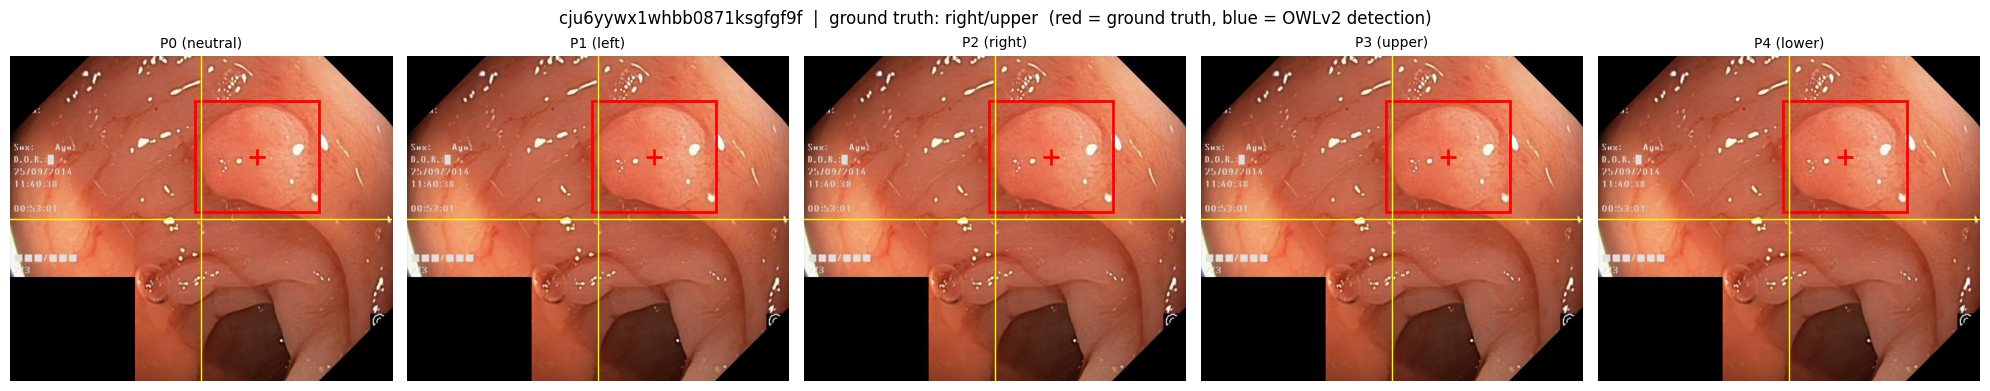

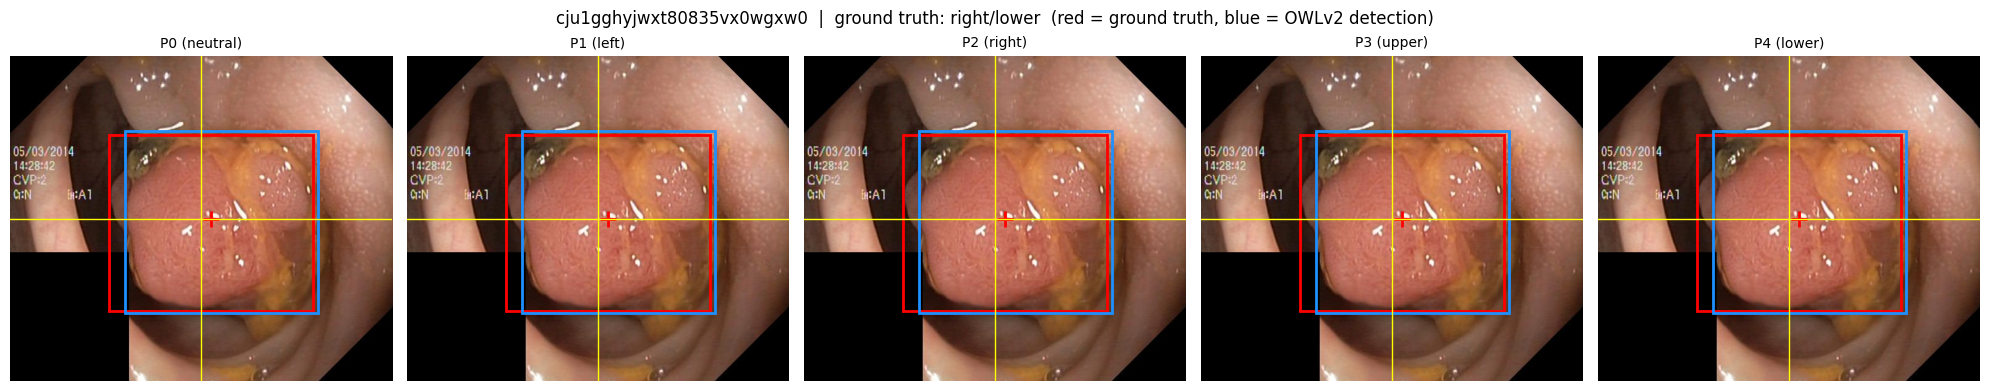

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_kvasir_owlv2/visualizations
           owlv2_correct_side  owlv2_no_shift  owlv2_iou  owlv2_dist_norm
prompt_id                                                                
P1                   0.100000        0.800000   0.443265         0.137408
P2                   0.900000        0.800000   0.443265         0.137408
P3                   0.307692        0.923077   0.572758         0.077570
P4                   0.571429        1.000000   0.650110         0.055702


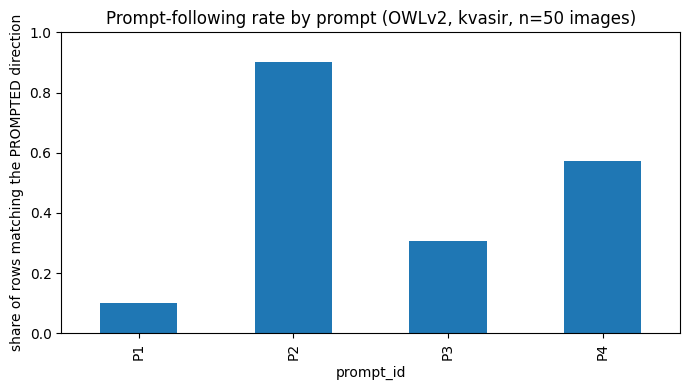

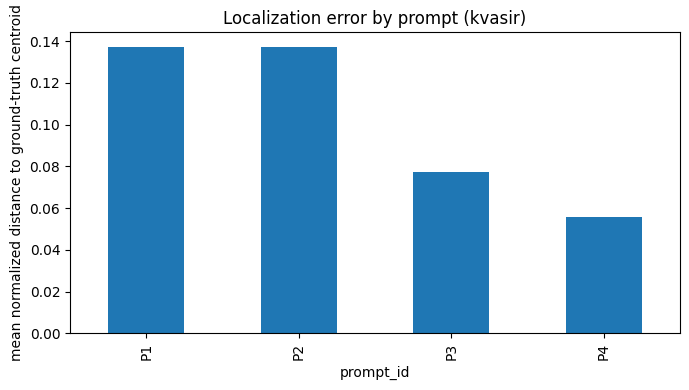

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_kvasir_owlv2/kvasir_owlv2_summary_by_prompt.csv
RQ2 (kvasir) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           owlv2_correct_side  owlv2_dist_norm
prompt_id                                     
P1                   0.333333         0.255905
P2                   1.000000         0.086623
P3                   0.571429         0.116168
P4                   1.000000         0.032540

RQ3 (kvasir) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           owlv2_correct_side  owlv2_dist_norm
prompt_id                                     
P1                   0.000000         0.086623
P2                   0.666667         0.255905
P3                   0.000000         0.032540
P4                   0.250000         0.073074

Processing dataset: isic
[ok] isic: loaded manifest with 250 rows, 50 images


OWLv2 inference (isic):   0%|          | 0/250 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/owlv2/processing_owlv2.py:201: FutureWarning: `post_process_object_detection` method is deprecated for OwlVitProcessor and will be removed in v5. Use `post_process_grounded_object_detection` instead.
  warnings.warn(


[ok] ran inference on 250 rows
[warn] 76 / 250 rows had a near-full-image OWLv2 box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 36 columns -> /content/drive/MyDrive/run_colab/results_isic_owlv2/isic_owlv2_results.csv


Rendering isic visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

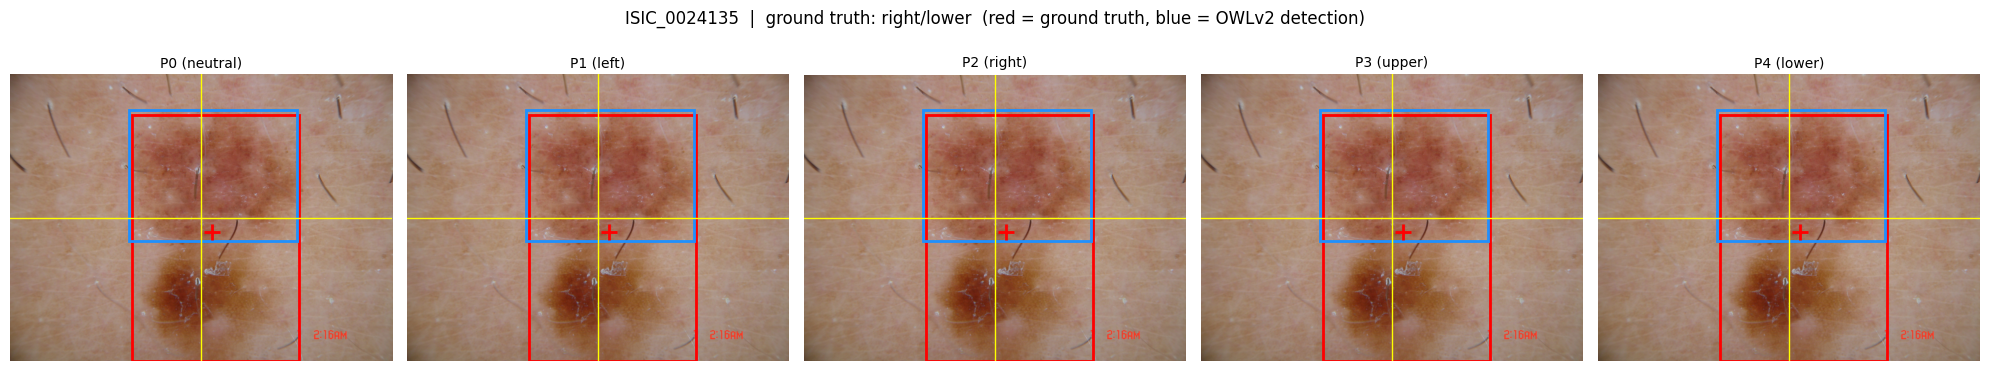

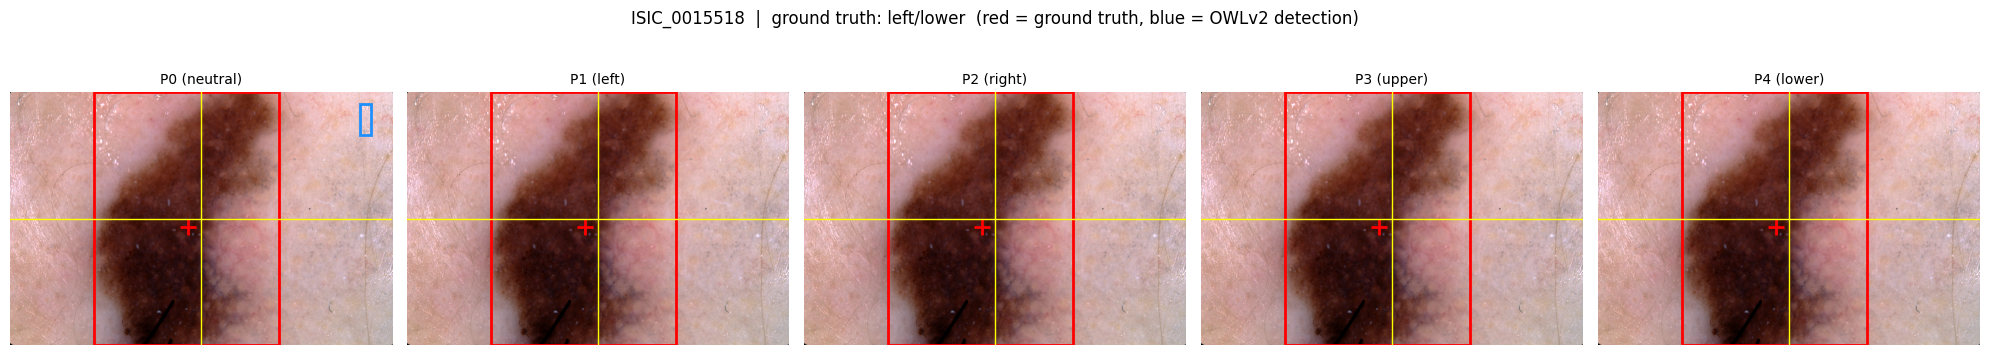

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_isic_owlv2/visualizations
           owlv2_correct_side  owlv2_no_shift  owlv2_iou  owlv2_dist_norm
prompt_id                                                                
P1                   0.466667        0.966667   0.773866         0.027645
P2                   0.571429        0.964286   0.763905         0.028949
P3                   0.666667        0.969697   0.780972         0.028069
P4                   0.314286        0.971429   0.787593         0.026664


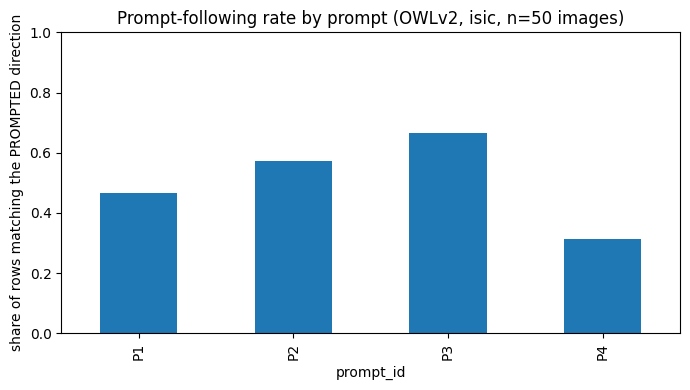

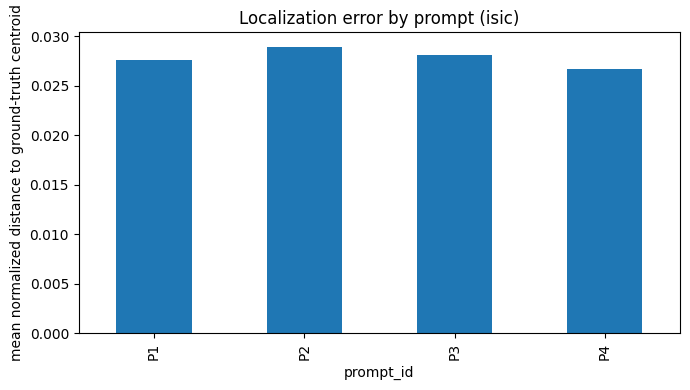

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_isic_owlv2/isic_owlv2_summary_by_prompt.csv
RQ2 (isic) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           owlv2_correct_side  owlv2_dist_norm
prompt_id                                     
P1                   1.000000         0.025242
P2                   1.000000         0.029747
P3                   0.944444         0.014849
P4                   0.666667         0.043933

RQ3 (isic) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           owlv2_correct_side  owlv2_dist_norm
prompt_id                                     
P1                   0.000000         0.029747
P2                   0.000000         0.027885
P3                   0.333333         0.043933
P4                   0.050000         0.013712

Processing dataset: lgg
[ok] lgg: loaded manifest with 250 rows, 50 images


OWLv2 inference (lgg):   0%|          | 0/250 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/owlv2/processing_owlv2.py:201: FutureWarning: `post_process_object_detection` method is deprecated for OwlVitProcessor and will be removed in v5. Use `post_process_grounded_object_detection` instead.
  warnings.warn(


[ok] ran inference on 250 rows
[warn] 0 / 250 rows had a near-full-image OWLv2 box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 36 columns -> /content/drive/MyDrive/run_colab/results_lgg_owlv2/lgg_owlv2_results.csv


Rendering lgg visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

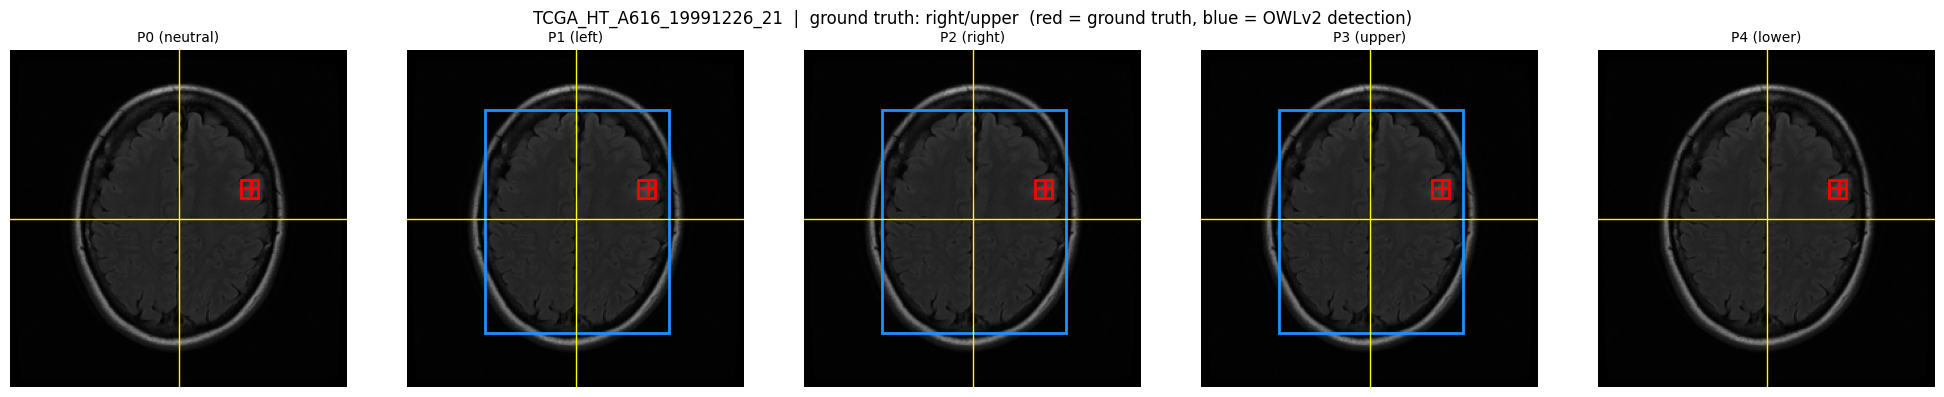

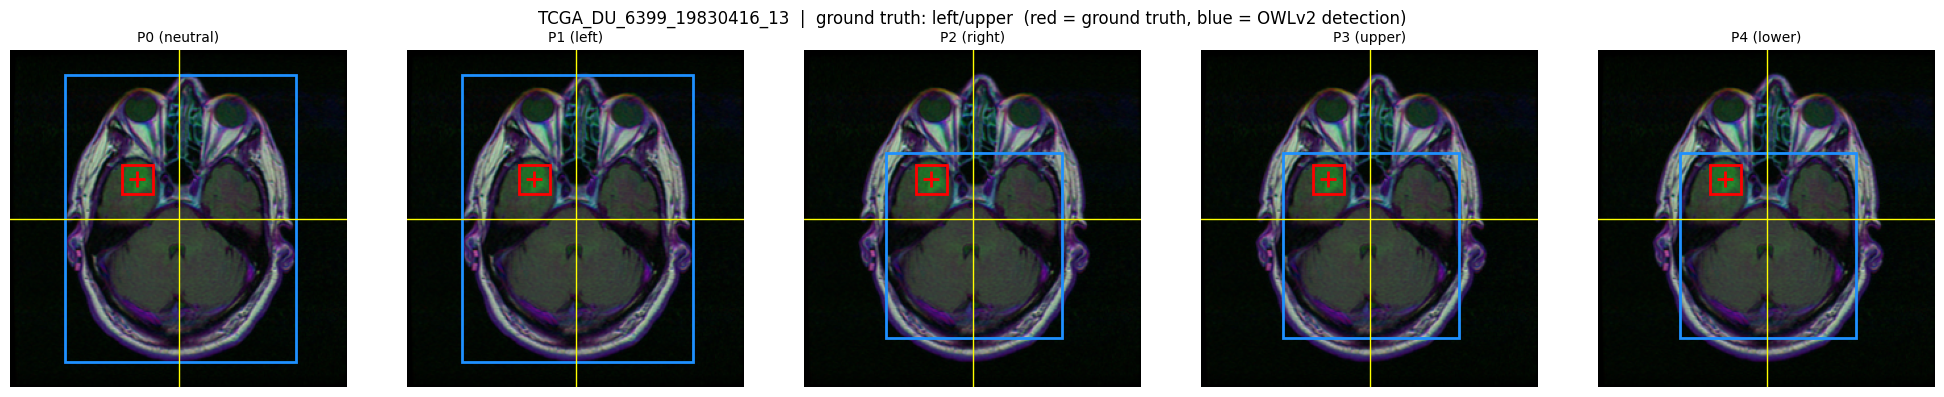

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_lgg_owlv2/visualizations
           owlv2_correct_side  owlv2_no_shift  owlv2_iou  owlv2_dist_norm
prompt_id                                                                
P1                   0.408163        0.857143   0.151717         0.116909
P2                   0.591837        0.833333   0.151996         0.117814
P3                   0.187500        0.880952   0.188020         0.112665
P4                   0.808511        0.880952   0.191856         0.111581


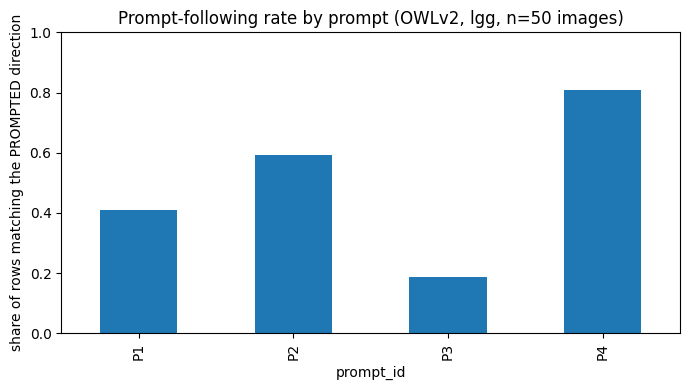

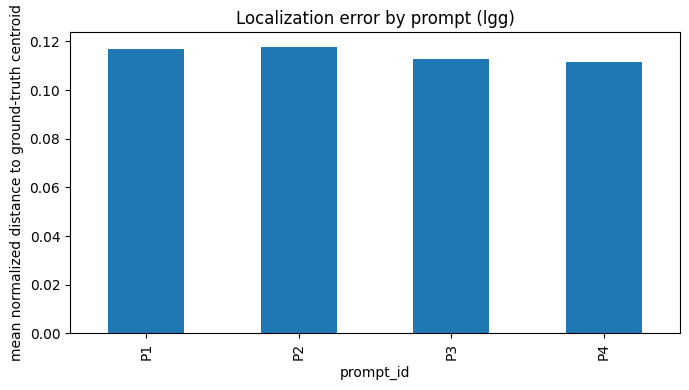

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_lgg_owlv2/lgg_owlv2_summary_by_prompt.csv
RQ2 (lgg) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           owlv2_correct_side  owlv2_dist_norm
prompt_id                                     
P1                   0.583333         0.125287
P2                   0.760000         0.108867
P3                   0.212121         0.109646
P4                   0.866667         0.119306

RQ3 (lgg) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           owlv2_correct_side  owlv2_dist_norm
prompt_id                                     
P1                   0.240000         0.108867
P2                   0.416667         0.127135
P3                   0.133333         0.119306
P4                   0.781250         0.107960

[ok] finished: ['kvasir', 'isic', 'lgg']


In [23]:
ALL_DATASETS = ["kvasir", "isic", "lgg"]

all_dfs = {}
for dataset_name in ALL_DATASETS:
    print(f"\n{'=' * 80}\nProcessing dataset: {dataset_name}\n{'=' * 80}")
    data_dir, out_dir, vis_dir = get_dataset_paths(dataset_name, f"results_{dataset_name}_owlv2")

    manifest_df = load_manifest(dataset_name, data_dir)
    result_df = run_owlv2_inference(model, processor, DEVICE, manifest_df, data_dir, desc=f"OWLv2 inference ({dataset_name})")
    result_df = score_predictions(result_df, data_dir)
    save_results(result_df, out_dir, dataset_name)
    render_visualizations(result_df, data_dir, vis_dir, dataset_name, show_first=2)
    aggregate_and_report(result_df, out_dir, dataset_name)
    report_rq2_rq3(result_df, dataset_name)

    all_dfs[dataset_name] = result_dfy

print("\n[ok] finished:", list(all_dfs.keys()))